# Tuần 03 — Thực hành kNN: 4 bài

Demo `01_Demo-kNN.ipynb` dừng ở việc **vote nhãn cho một mẫu test**.

Notebook này có **4 bài**. Mỗi bài là một bộ dữ liệu trên Kaggle. Cả 4 bài đều làm.

Viết hàm kNN một lần ở phần chung (NumPy, không dùng `KNeighborsClassifier`), rồi áp vào từng bài. Điền các ô có `???`. Giữ `np.random.seed(3000)`.

Tải đủ 4 file, đặt vào thư mục `data/`:

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Iris Species | https://www.kaggle.com/datasets/uciml/iris | `data/Iris.csv` |
| 2 | Palmer Penguins | https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data | `data/penguins_size.csv` |
| 3 | Heart Failure Prediction | https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction | `data/heart.csv` |
| 4 | Mushroom Classification | https://www.kaggle.com/datasets/uciml/mushroom-classification | `data/mushrooms.csv` |


In [1]:
print('hi')

hi


In [3]:
pip install numpy 

     ---------------------------------------- 12.6/12.6 MB 6.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install matplotlib

     ---------------------------------------- 9.3/9.3 MB 4.9 MB/s eta 0:00:00
     -------------------------------------- 225.2/225.2 kB 3.4 MB/s eta 0:00:00
     ---------------------------------------- 1.6/1.6 MB 4.0 MB/s eta 0:00:00
     ---------------------------------------- 70.7/70.7 kB 3.8 MB/s eta 0:00:00
     ---------------------------------------- 7.2/7.2 MB 4.1 MB/s eta 0:00:00
     -------------------------------------- 126.4/126.4 kB 3.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import LabelEncoder

np.set_printoptions(precision=3, suppress=True)


Matplotlib is building the font cache; this may take a moment.


## Phần chung — hàm kNN

Các bài bên dưới gọi lại 4 hàm này.

**Chuẩn hóa min–max**, min/max tính trên từng cột của `x_train`, rồi áp cùng hai mốc đó cho `x_test`. Cột nào `max == min` thì giữ nguyên.

$$
x' = \frac{x - x_{min}}{x_{max} - x_{min}}
$$

**Khoảng cách Euclid** từ một mẫu test tới mọi dòng train:

$$
d_i = \sqrt{\sum_j (test_j - train_{i,j})^2}
$$

**Một mẫu:** lấy `K` chỉ số gần nhất (`np.argsort`), vote nhãn xuất hiện nhiều nhất. Hòa thì `np.argmax` trên `counts` chọn nhãn có mã nhỏ hơn.

**Cả tập test:** gọi dự đoán từng mẫu, trả về mảng nhãn cùng độ dài `x_test`.


In [7]:
def chuan_hoa_minmax(x_train, x_test):
    # Tính min và max trên từng cột của x_train
    x_min = np.min(x_train, axis=0)
    x_max = np.max(x_train,axis=0)
    # Tính mẫu số
    denominator = x_max - x_min

    # Cột có max == min thì giữ nguyên
    x_train_scaled = np.zeros_like(x_train, dtype=float)
    x_test_scaled = np.zeros_like(x_test, dtype=float)

    # Những cột không phải hằng số
    mask = denominator != 0

    x_train_scaled[:, mask] = (
        (x_train[:, mask] - x_min[mask])
        / denominator[mask]
    )

    x_test_scaled[:, mask] = (
        (x_test[:, mask] - x_min[mask])
        / denominator[mask]
    )

    # Cột max == min được giữ nguyên
    x_train_scaled[:, ~mask] = x_train[:, ~mask]
    x_test_scaled[:, ~mask] = x_test[:, ~mask]
    
    return x_train_scaled, x_test_scaled


def tinh_khoang_cach(test_s, x_train):
    """test_s shape (n_feature,), x_train shape (n_train, n_feature).
    Trả về khoảng cách shape (n_train,).
    """
    # Hiệu giữa test_s và từng dòng của x_train
    diff = x_train - test_s

    # Khoảng cách Euclid
    distances = np.sqrt(np.sum(diff ** 2, axis=1))

    return distances


def du_doan_1_mau(test_s, x_train, y_train, K):
    # Tính khoảng cách từ test_s đến toàn bộ x_train
    distances = tinh_khoang_cach(test_s, x_train)

    # Lấy K chỉ số có khoảng cách nhỏ nhất
    nearest_indices = np.argsort(distances)[:K]

    # Lấy nhãn của K hàng xóm gần nhất
    nearest_labels = y_train[nearest_indices]

    # Đếm số lần xuất hiện của từng nhãn
    labels, counts = np.unique(nearest_labels, return_counts=True)

    # np.argmax chọn vị trí có count lớn nhất.
    # Nếu hòa, np.unique đã sắp xếp labels tăng dần,
    # nên nhãn nhỏ hơn sẽ được chọn.
    winner = labels[np.argmax(counts)]

    return winner


def du_doan_tap(x_test, x_train, y_train, K):
    # Dự đoán từng mẫu test
    predictions = []

    for test_s in x_test:
        pred = du_doan_1_mau(test_s, x_train, y_train, K)
        predictions.append(pred)

    return np.array(predictions)


In [ ]:
def chia_train_test(X, Y, ty_le=0.8, seed=3000):
    np.random.seed(seed)
    rand_indices = np.arange(len(Y))
    np.random.shuffle(rand_indices)
    n_train = int(ty_le * len(Y))
    train_idx = rand_indices[:n_train]
    test_idx = rand_indices[n_train:]
    return X[train_idx], Y[train_idx], X[test_idx], Y[test_idx]


def accuracy(y_pred, y_test):
    return np.mean(y_pred == y_test)


def ve_accuracy_theo_K(x_train, y_train, x_test, y_test, ds_K=None):
    if ds_K is None:
        ds_K = [1, 3, 5, 7, 9, 11, 13, 15]
    ds_acc = [accuracy(du_doan_tap(x_test, x_train, y_train, K), y_test) for K in ds_K]
    print(list(zip(ds_K, np.round(ds_acc, 3))))
    plt.figure(figsize=(6, 4))
    plt.plot(ds_K, ds_acc, marker='o')
    plt.xlabel('K')
    plt.ylabel('accuracy')
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.show()
    return ds_K, ds_acc


---

# Bài 1 — Iris

Nguồn: https://www.kaggle.com/datasets/uciml/iris

File `data/Iris.csv`. 150 bông, 3 loài.

Cột: `Id`, `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, `Species`.

- Bỏ cột `Id`. Đó là số thứ tự, không phải số đo của hoa.
- Bốn cột đo là số (cm). Nhãn `Species` là chữ: dùng `LabelEncoder`.
- Chuẩn hóa min–max, rồi so sánh accuracy khi **có** và **không** chuẩn hóa (`K=5`).
- In kiểm tra mẫu test đầu tiên (khoảng cách K láng giềng, nhãn của họ, nhãn đoán, nhãn thật), rồi vẽ accuracy theo K.


In [8]:
raw_iris = np.genfromtxt('data/Iris.csv', delimiter=',', dtype=str, skip_header=1)
print(raw_iris.shape)
print(raw_iris[0])

# TODO: X_iris float (bỏ Id), Y_iris int
# X: bỏ Id, lấy 4 cột số đo
X_iris = raw_iris[:, 1:5].astype(float)

# Y: lấy Species và mã hóa thành số
label_encoder = LabelEncoder()
Y_iris = label_encoder.fit_transform(raw_iris[:, 5])

print(X_iris.shape, Y_iris.shape)
print(np.unique(Y_iris, return_counts=True))


(150, 6)
['1' '5.1' '3.5' '1.4' '0.2' 'Iris-setosa']
(150, 4) (150,)
(array([0, 1, 2]), array([50, 50, 50]))


In [11]:
import numpy as np

def chia_train_test(X, Y, test_size=0.2, random_state=42):
    np.random.seed(random_state)

    # Tạo chỉ số và xáo trộn
    indices = np.arange(len(X))
    np.random.shuffle(indices)

    # Số mẫu test
    n_test = int(len(X) * test_size)

    # Chỉ số test và train
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]

    # Chia dữ liệu
    x_train = X[train_indices]
    y_train = Y[train_indices]

    x_test = X[test_indices]
    y_test = Y[test_indices]

    return x_train, y_train, x_test, y_test


In [19]:
def accuracy(y_pred, y_true):
    return np.mean(y_pred == y_true)


In [18]:
import matplotlib.pyplot as plt

def ve_accuracy_theo_K(x_train, y_train, x_test, y_test):
    K_values = range(1, 21)
    accuracies = []

    for K in K_values:
        y_pred = du_doan_tap(x_test, x_train, y_train, K)
        acc = accuracy(y_pred, y_test)
        accuracies.append(acc)

    plt.figure(figsize=(8, 5))
    plt.plot(K_values, accuracies, marker='o')
    plt.xlabel('K')
    plt.ylabel('Accuracy')
    plt.title('Accuracy theo K')
    plt.xticks(list(K_values))
    plt.grid(True)
    plt.show()


K khoảng cách nhỏ nhất: [0.093 0.096 0.119 0.127 0.13 ]
Nhãn K láng giềng: [1 1 1 1 1]
Nhãn dự đoán: 1
Nhãn thật: 1
accuracy K=5, đã chuẩn hóa: 1.0
accuracy K=5, chưa chuẩn hóa: 1.0


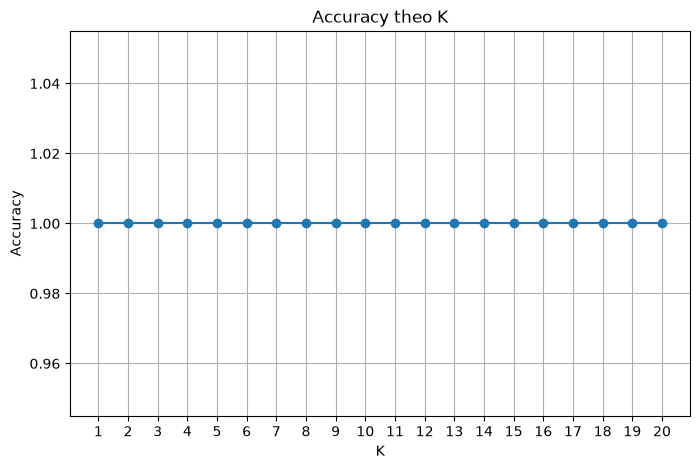

In [21]:
x_train, y_train, x_test, y_test = chia_train_test(X_iris, Y_iris)

x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

K = 5
# TODO: in K khoảng cách nhỏ nhất, nhãn K láng giềng, nhãn dự đoán, y_test[0]

# Kiểm tra mẫu test đầu tiên
distances = tinh_khoang_cach(x_test_s[0], x_train_s)

nearest_indices = np.argsort(distances)[:K]

nearest_distances = distances[nearest_indices]
nearest_labels = y_train[nearest_indices]

y_pred = du_doan_1_mau(
    x_test_s[0],
    x_train_s,
    y_train,
    K
)

print("K khoảng cách nhỏ nhất:", nearest_distances)
print("Nhãn K láng giềng:", nearest_labels)
print("Nhãn dự đoán:", y_pred)
print("Nhãn thật:", y_test[0])

print(
    'accuracy K=5, đã chuẩn hóa:',
    accuracy(
        du_doan_tap(x_test_s, x_train_s, y_train, K),
        y_test
    )
)

print(
    'accuracy K=5, chưa chuẩn hóa:',
    accuracy(
        du_doan_tap(x_test, x_train, y_train, K),
        y_test
    )
)

ve_accuracy_theo_K(
    x_train_s,
    y_train,
    x_test_s,
    y_test
)


**Nộp kèm bài 1**

1. `X` có bao nhiêu dòng, bao nhiêu cột? Có bao nhiêu lớp?
2. Accuracy tại `K=5` khi có chuẩn hóa và khi không chuẩn hóa chênh nhau thế nào? Vì sao với Iris mức chênh thường nhỏ?
3. Vì sao không đưa cột `Id` vào feature?


In [22]:
# Bài 1
# 1. 
print("1.")
print("X có", X_iris.shape[0], "dòng và", X_iris.shape[1], "cột.")
print("Có", len(np.unique(Y_iris)), "lớp.")
print("Mỗi lớp có", np.unique(Y_iris, return_counts=True)[1], "mẫu.")

# 2. 
acc_chuan_hoa = accuracy(
    du_doan_tap(x_test_s, x_train_s, y_train, K),
    y_test
)

acc_khong_chuan_hoa = accuracy(
    du_doan_tap(x_test, x_train, y_train, K),
    y_test
)

print("\n2.")
print("Accuracy K=5, có chuẩn hóa:", acc_chuan_hoa)
print("Accuracy K=5, không chuẩn hóa:", acc_khong_chuan_hoa)
print("Chênh lệch accuracy:", abs(acc_chuan_hoa - acc_khong_chuan_hoa))

print("Với Iris, mức chênh thường nhỏ vì các đặc trưng đều là kích thước")
print("theo cm và các đặc trưng, đặc biệt là chiều dài/rộng cánh hoa,")
print("phân biệt các lớp khá rõ ràng.")
# 3.
print("\n3.")
print("Không đưa cột Id vào feature vì Id chỉ là số thứ tự/định danh của mẫu,")
print("không thể hiện đặc điểm của bông hoa.")
print("Nếu đưa Id vào, khoảng cách Euclid sẽ bị ảnh hưởng bởi Id,")
print("có thể làm kết quả kNN bị sai lệch.")

1.
X có 150 dòng và 4 cột.
Có 3 lớp.
Mỗi lớp có [50 50 50] mẫu.

2.
Accuracy K=5, có chuẩn hóa: 1.0
Accuracy K=5, không chuẩn hóa: 1.0
Chênh lệch accuracy: 0.0
Với Iris, mức chênh thường nhỏ vì các đặc trưng đều là kích thước
theo cm và các đặc trưng, đặc biệt là chiều dài/rộng cánh hoa,
phân biệt các lớp khá rõ ràng.

3.
Không đưa cột Id vào feature vì Id chỉ là số thứ tự/định danh của mẫu,
không thể hiện đặc điểm của bông hoa.
Nếu đưa Id vào, khoảng cách Euclid sẽ bị ảnh hưởng bởi Id,
có thể làm kết quả kNN bị sai lệch.


---

# Bài 2 — Palmer Penguins

Nguồn: https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data

File `data/penguins_size.csv`. Đoán loài chim cánh cụt.

Cột: `species`, `island`, `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex`.

- Bỏ mọi dòng có ô trống hoặc `NA`.
- Nhãn là `species`.
- `island` và `sex` là chữ: `LabelEncoder` **từng cột**.
- Bốn cột đo là số: `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`.
- Bắt buộc chuẩn hóa. `body_mass_g` khoảng vài nghìn, chiều dài mỏ khoảng vài chục. Không chuẩn hóa thì khoảng cách gần như chỉ còn khối lượng.


In [23]:
raw_pen = np.genfromtxt('data/penguins_size.csv', delimiter=',', dtype=str, skip_header=1)
print('trước khi bỏ dòng thiếu:', raw_pen.shape)

# TODO: bỏ dòng có '' hoặc 'NA', rồi tạo X_pen (float) và Y_pen (int)
from sklearn.preprocessing import LabelEncoder

# Bỏ các dòng có ô trống '' hoặc 'NA'
mask = np.all((raw_pen != '') & (raw_pen != 'NA'), axis=1)
clean_pen = raw_pen[mask]

# Các cột feature
# island, culmen_length_mm, culmen_depth_mm,
# flipper_length_mm, body_mass_g, sex
island = clean_pen[:, 1]
X_measure = clean_pen[:, 2:6].astype(float)
sex = clean_pen[:, 6]

# LabelEncoder cho island
le_island = LabelEncoder()
island_encoded = le_island.fit_transform(island)

# LabelEncoder cho sex
le_sex = LabelEncoder()
sex_encoded = le_sex.fit_transform(sex)

# Ghép các feature thành X
X_pen = np.column_stack([
    island_encoded,
    X_measure,
    sex_encoded
]).astype(float)

# Mã hóa species thành Y
le_species = LabelEncoder()
Y_pen = le_species.fit_transform(clean_pen[:, 0])

print('sau khi bỏ dòng thiếu:', X_pen.shape, Y_pen.shape)
print(np.unique(Y_pen, return_counts=True))


trước khi bỏ dòng thiếu: (344, 7)
sau khi bỏ dòng thiếu: (334, 6) (334,)
(array([0, 1, 2]), array([146,  68, 120]))


accuracy K=5, đã chuẩn hóa: 0.9848484848484849
accuracy K=5, chưa chuẩn hóa: 0.8181818181818182


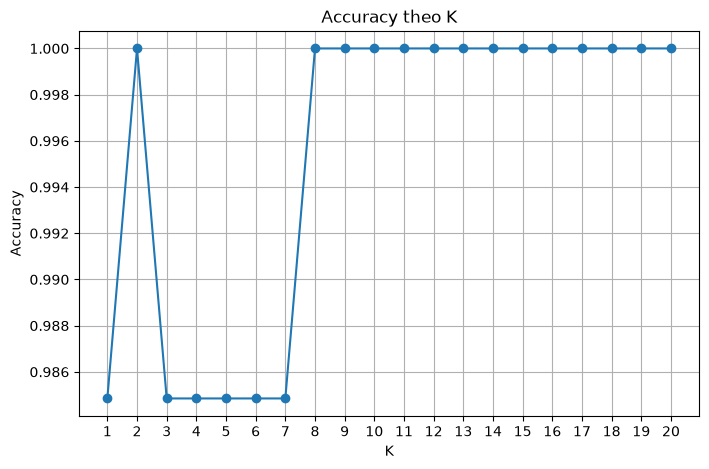

In [24]:
x_train, y_train, x_test, y_test = chia_train_test(X_pen, Y_pen)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5, đã chuẩn hóa:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
print('accuracy K=5, chưa chuẩn hóa:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))

ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 2**

1. Bỏ bao nhiêu dòng vì thiếu dữ liệu?
2. Accuracy `K=5` khi chưa chuẩn hóa thấp hơn bản đã chuẩn hóa ra sao? Cột nào kéo khoảng cách Euclid?
3. `K` nào cho accuracy cao nhất trên đồ thị?


In [26]:
# Bài 2
# 1.
so_dong_truoc = raw_pen.shape[0]
so_dong_sau = X_pen.shape[0]
so_dong_bo = so_dong_truoc - so_dong_sau

print("1.")
print("Số dòng trước khi bỏ:", so_dong_truoc)
print("Số dòng sau khi bỏ:", so_dong_sau)
print("Số dòng bị bỏ vì thiếu dữ liệu:", so_dong_bo)
# 2.
acc_chuan_hoa = accuracy(
    du_doan_tap(x_test_s, x_train_s, y_train, 5),
    y_test
)

acc_khong_chuan_hoa = accuracy(
    du_doan_tap(x_test, x_train, y_train, 5),
    y_test
)

print("\n2.")
print("Accuracy K=5, đã chuẩn hóa:", acc_chuan_hoa)
print("Accuracy K=5, chưa chuẩn hóa:", acc_khong_chuan_hoa)
print("Chênh lệch:", acc_chuan_hoa - acc_khong_chuan_hoa)

print("Cột kéo khoảng cách Euclid chủ yếu là body_mass_g")
print("vì body_mass_g có giá trị vài nghìn, lớn hơn nhiều so với")
print("các đặc trưng như culmen_length_mm và culmen_depth_mm.")

# 3.
K_values = range(1, 21)
accuracies = []

for k in K_values:
    y_pred = du_doan_tap(x_test_s, x_train_s, y_train, k)
    acc = accuracy(y_pred, y_test)
    accuracies.append(acc)

best_index = np.argmax(accuracies)
best_K = list(K_values)[best_index]
best_accuracy = accuracies[best_index]

print("\n3.")
print("K có accuracy cao nhất:", best_K)
print("Accuracy cao nhất:", best_accuracy)


1.
Số dòng trước khi bỏ: 344
Số dòng sau khi bỏ: 334
Số dòng bị bỏ vì thiếu dữ liệu: 10

2.
Accuracy K=5, đã chuẩn hóa: 0.9848484848484849
Accuracy K=5, chưa chuẩn hóa: 0.8181818181818182
Chênh lệch: 0.16666666666666663
Cột kéo khoảng cách Euclid chủ yếu là body_mass_g
vì body_mass_g có giá trị vài nghìn, lớn hơn nhiều so với
các đặc trưng như culmen_length_mm và culmen_depth_mm.

3.
K có accuracy cao nhất: 2
Accuracy cao nhất: 1.0


---

# Bài 3 — Heart Failure Prediction

Nguồn: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

File `data/heart.csv`. 918 dòng. Đoán có bệnh tim hay không. Cùng kiểu bài với demo tình trạng xe.

Cột theo đúng thứ tự trong file:

`Age`, `Sex`, `ChestPainType`, `RestingBP`, `Cholesterol`, `FastingBS`, `RestingECG`, `MaxHR`, `ExerciseAngina`, `Oldpeak`, `ST_Slope`, `HeartDisease`.

- Nhãn `HeartDisease` đã là `0` / `1`.
- Cột chữ, `LabelEncoder` từng cột: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`.
- Cột số: `Age`, `RestingBP`, `Cholesterol`, `FastingBS`, `MaxHR`, `Oldpeak`.
- Ghép các cột đã mã hóa thành một ma trận `X` kiểu float, rồi chuẩn hóa min–max.
- Hai lớp, nên các `K` đem thử là số lẻ.


In [27]:
raw_heart = np.genfromtxt('data/heart.csv', delimiter=',', dtype=str, skip_header=1)
print(raw_heart.shape)
print(raw_heart[0])

# TODO: X_heart float, Y_heart int
from sklearn.preprocessing import LabelEncoder

# Các cột chữ
# Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope

le_sex = LabelEncoder()
sex_encoded = le_sex.fit_transform(raw_heart[:, 1])

le_chest = LabelEncoder()
chest_encoded = le_chest.fit_transform(raw_heart[:, 2])

le_ecg = LabelEncoder()
ecg_encoded = le_ecg.fit_transform(raw_heart[:, 6])

le_angina = LabelEncoder()
angina_encoded = le_angina.fit_transform(raw_heart[:, 8])

le_slope = LabelEncoder()
slope_encoded = le_slope.fit_transform(raw_heart[:, 10])

# Các cột số
# Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak
numeric_data = raw_heart[:, [0, 3, 4, 5, 7, 9]].astype(float)

# Ghép tất cả feature thành X
X_heart = np.column_stack([
    numeric_data[:, 0],   # Age
    sex_encoded,          # Sex
    chest_encoded,        # ChestPainType
    numeric_data[:, 1],   # RestingBP
    numeric_data[:, 2],   # Cholesterol
    numeric_data[:, 3],   # FastingBS
    ecg_encoded,          # RestingECG
    numeric_data[:, 4],   # MaxHR
    angina_encoded,       # ExerciseAngina
    numeric_data[:, 5],   # Oldpeak
    slope_encoded         # ST_Slope
]).astype(float)

# Nhãn HeartDisease: 0 / 1
Y_heart = raw_heart[:, 11].astype(int)

print(X_heart.shape, Y_heart.shape)
print(np.unique(Y_heart, return_counts=True))


(918, 12)
['40' 'M' 'ATA' '140' '289' '0' 'Normal' '172' 'N' '0' 'Up' '0']
(918, 11) (918,)
(array([0, 1]), array([410, 508]))


accuracy K=5: 0.8524590163934426


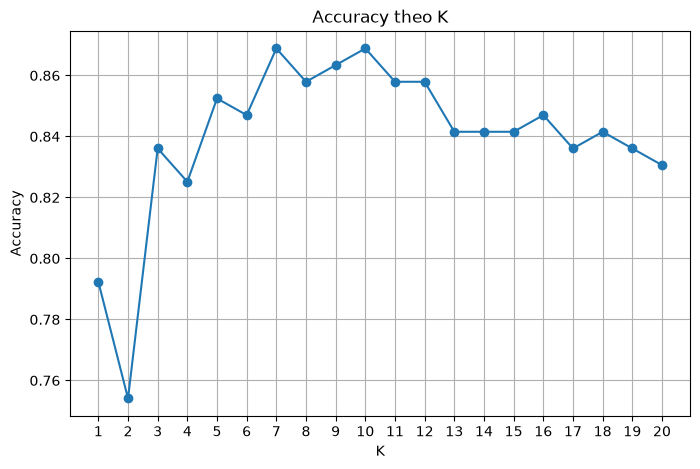

In [28]:
x_train, y_train, x_test, y_test = chia_train_test(X_heart, Y_heart)
x_train_s, x_test_s = chuan_hoa_minmax(x_train, x_test)

print('accuracy K=5:', accuracy(du_doan_tap(x_test_s, x_train_s, y_train, 5), y_test))
ve_accuracy_theo_K(x_train_s, y_train, x_test_s, y_test)


**Nộp kèm bài 3**

1. Có bao nhiêu người trong tập test? Tỉ lệ lớp `0` và `1` trên toàn bộ dữ liệu là bao nhiêu?
2. Accuracy cao nhất và `K` tương ứng?
3. Vì sao với bài 2 lớp nên chọn `K` lẻ?


In [29]:
# Bài 3
# 1.
so_nguoi_test = len(y_test)

so_lop = np.unique(Y_heart, return_counts=True)
labels = so_lop[0]
counts = so_lop[1]

print("1.")
print("Số người trong tập test:", so_nguoi_test)

for label, count in zip(labels, counts):
    ty_le = count / len(Y_heart) * 100
    print(f"Lớp {label}: {count} người, chiếm {ty_le:.2f}%")

# 2.
K_values = range(1, 20, 2)   # chỉ thử K lẻ
accuracies = []

for K in K_values:
    y_pred = du_doan_tap(x_test_s, x_train_s, y_train, K)
    acc = accuracy(y_pred, y_test)
    accuracies.append(acc)

best_index = np.argmax(accuracies)
best_K = list(K_values)[best_index]
best_accuracy = accuracies[best_index]

print("\n2.")
print("Accuracy cao nhất:", best_accuracy)
print("K tương ứng:", best_K)

# 3.
print("\n3.")
print("Vì bài toán có 2 lớp nên chọn K lẻ để hạn chế trường hợp hòa phiếu.")
print("Ví dụ K=4 có thể có 2 láng giềng lớp 0 và 2 láng giềng lớp 1.")
print("K=5 thì không thể chia đều giữa 2 lớp, nên luôn có lớp chiếm đa số.")


1.
Số người trong tập test: 183
Lớp 0: 410 người, chiếm 44.66%
Lớp 1: 508 người, chiếm 55.34%

2.
Accuracy cao nhất: 0.8688524590163934
K tương ứng: 7

3.
Vì bài toán có 2 lớp nên chọn K lẻ để hạn chế trường hợp hòa phiếu.
Ví dụ K=4 có thể có 2 láng giềng lớp 0 và 2 láng giềng lớp 1.
K=5 thì không thể chia đều giữa 2 lớp, nên luôn có lớp chiếm đa số.


---

# Bài 4 — Mushroom Classification

Nguồn: https://www.kaggle.com/datasets/uciml/mushroom-classification

File `data/mushrooms.csv`. Đoán nấm ăn được (`e`) hay độc (`p`).

Mọi cột đều là chữ, cùng kiểu demo xe. Cột 0 là nhãn `class`. Các cột còn lại là feature.

- Bỏ dòng nào còn giá trị `?`.
- `LabelEncoder` **từng cột** feature, rồi mã hóa riêng cột nhãn. Giống đoạn mã hóa trong demo xe.
- **Không** chuẩn hóa min–max. Mã `LabelEncoder` chỉ là tên nhóm được đánh số, không phải số đo cùng đơn vị.
- Tập này vài nghìn dòng. `tinh_khoang_cach` cần tính một lần cho cả `x_train` (vector), không viết vòng `for` từng dòng train.


In [30]:
raw_mush = np.genfromtxt('data/mushrooms.csv', delimiter=',', dtype=str, skip_header=1)
print('trước khi bỏ dòng có ?:', raw_mush.shape)

# TODO: bỏ dòng chứa '?', X_mush float, Y_mush int
from sklearn.preprocessing import LabelEncoder

# Bỏ các dòng có giá trị '?'
mask = np.all(raw_mush != '?', axis=1)
clean_mush = raw_mush[mask]

# Cột 0 là nhãn class
# Các cột 1 trở đi là feature

# Encode từng cột feature
encoded_features = []

for col in range(1, clean_mush.shape[1]):
    le = LabelEncoder()
    encoded_col = le.fit_transform(clean_mush[:, col])
    encoded_features.append(encoded_col)

# Ghép các feature thành ma trận X
X_mush = np.column_stack(encoded_features).astype(float)

# Encode riêng cột nhãn class
le_class = LabelEncoder()
Y_mush = le_class.fit_transform(clean_mush[:, 0]).astype(int)

print(X_mush.shape, Y_mush.shape)
print(np.unique(Y_mush, return_counts=True))


trước khi bỏ dòng có ?: (8124, 23)
(5644, 22) (5644,)
(array([0, 1]), array([3488, 2156]))


accuracy K=5: 0.99822695035461


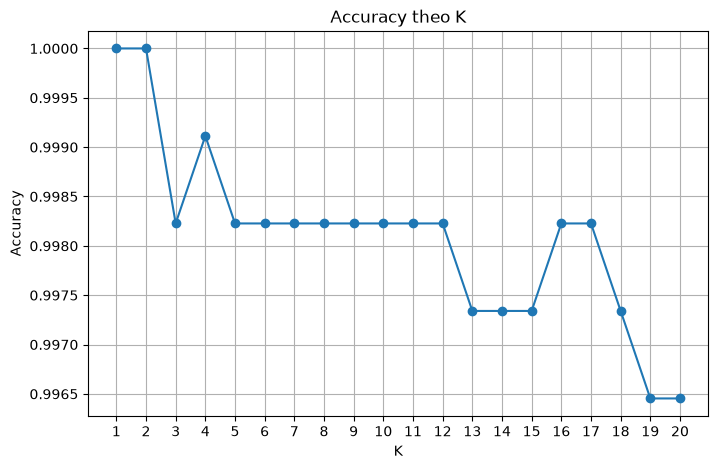

In [31]:
x_train, y_train, x_test, y_test = chia_train_test(X_mush, Y_mush)

# Không gọi chuan_hoa_minmax
print('accuracy K=5:', accuracy(du_doan_tap(x_test, x_train, y_train, 5), y_test))
ve_accuracy_theo_K(x_train, y_train, x_test, y_test)


**Nộp kèm bài 4**

1. Còn bao nhiêu dòng sau khi bỏ `?`? Bao nhiêu feature?
2. Accuracy cao nhất và `K` tương ứng?
3. Bài này giống demo tình trạng xe ở bước nào, và khác bài 1–3 ở chỗ nào (chuẩn hóa)?


In [32]:
# Bài 4
# 1.
so_dong_truoc = raw_mush.shape[0]
so_dong_sau = X_mush.shape[0]
so_dong_bo = so_dong_truoc - so_dong_sau
so_feature = X_mush.shape[1]

print("1.")
print("Số dòng trước khi bỏ '?':", so_dong_truoc)
print("Số dòng sau khi bỏ '?':", so_dong_sau)
print("Số dòng bị bỏ:", so_dong_bo)
print("Số feature:", so_feature)
# 2.
K_values = range(1, 20, 2)   # thử các K lẻ
accuracies = []

for K in K_values:
    y_pred = du_doan_tap(x_test, x_train, y_train, K)
    acc = accuracy(y_pred, y_test)
    accuracies.append(acc)

best_index = np.argmax(accuracies)
best_K = list(K_values)[best_index]
best_accuracy = accuracies[best_index]

print("\n2.")
print("Accuracy cao nhất:", best_accuracy)
print("K tương ứng:", best_K)
# 3.
print("\n3.")
print("Bài này giống demo tình trạng xe ở bước:")
print("- Dữ liệu đều là dạng categorical (chữ).")
print("- Dùng LabelEncoder cho từng cột feature.")
print("- Mã hóa riêng cột nhãn.")
print("- Sau đó đưa dữ liệu đã mã hóa vào kNN.")

print("\nKhác bài 1–3:")
print("- Không chuẩn hóa min-max.")
print("- Các giá trị sau LabelEncoder chỉ là mã nhóm,")
print("  không phải số đo có cùng đơn vị.")
print("- Vì vậy bài này sử dụng trực tiếp X_mush,")
print("  không sử dụng x_train_s và x_test_s.")

1.
Số dòng trước khi bỏ '?': 8124
Số dòng sau khi bỏ '?': 5644
Số dòng bị bỏ: 2480
Số feature: 22

2.
Accuracy cao nhất: 1.0
K tương ứng: 1

3.
Bài này giống demo tình trạng xe ở bước:
- Dữ liệu đều là dạng categorical (chữ).
- Dùng LabelEncoder cho từng cột feature.
- Mã hóa riêng cột nhãn.
- Sau đó đưa dữ liệu đã mã hóa vào kNN.

Khác bài 1–3:
- Không chuẩn hóa min-max.
- Các giá trị sau LabelEncoder chỉ là mã nhóm,
  không phải số đo có cùng đơn vị.
- Vì vậy bài này sử dụng trực tiếp X_mush,
  không sử dụng x_train_s và x_test_s.
